In [1]:
import os
from langchain_community.document_loaders import TextLoader,PyPDFLoader,WebBaseLoader
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import FAISS
from typing import List,TypedDict,Annotated
from pydantic import BaseModel
from langchain_classic.schema import Document
from langchain_community.tools import tool,WikipediaQueryRun
from langchain_tavily import TavilySearch
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_classic.utilities import WikipediaAPIWrapper


USER_AGENT environment variable not set, consider setting it to identify your requests.


In [2]:
!ollama pull deepseek-v2

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13 KB                         
pulling 19f2fb9e8bc6: 100% ▕██████████████████▏   32 B                         
pulling 2b2c35718a16: 100% ▕██████████████████▏  494 B                         
verifying sha256 digest 
writing manifest 
removing unused layers ⠋ pulling manifest 
pulling d8d69f2a1bfa: 100% ▕██████████████████▏ 8.9 GB                         
pulling b321cd7de6c7: 100% ▕██████████████████▏  111 B                         
pulling 4bb71764481f: 100% ▕██████████████████▏  13

In [48]:
from dotenv import load_dotenv
load_dotenv()
from langchain.chat_models import init_chat_model
os.environ["OLLAMA_API_KEY"]=os.getenv("OLLAMA_API_KEY")
os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")
os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")
os.environ["GOOGLE_API_KEY"]=os.getenv("GOOGLE_API_KEY")

llm=init_chat_model(
    "gemini-3.1-flash-lite",
    model_provider="google_genai",
    temperature=0.1
)

In [49]:
llm.invoke("Hello,Tell me about yourself").content

[{'type': 'text',
  'text': 'Hello! I am a large language model, trained by Google.\n\nThink of me as a knowledgeable, creative, and versatile virtual assistant. I don’t have a physical form, a personal life, or feelings, but I have been trained on a massive amount of text data, which allows me to help you with a wide variety of tasks.\n\nHere are a few things I can do for you:\n\n*   **Answering questions:** From science and history to pop culture and trivia.\n*   **Writing and editing:** I can help you draft emails, write essays, create stories, polish your grammar, or brainstorm ideas for projects.\n*   **Coding:** I can write, debug, and explain code in many different programming languages.\n*   **Summarization:** If you have a long article or document, I can condense it into key points for you.\n*   **Translation:** I can translate text between dozens of different languages.\n*   **Learning:** I can explain complex topics in simple terms, like I’m teaching a beginner.\n\n**What I’

In [38]:
tavily_tool=TavilySearch()
tavily_tool.invoke("Give top 3 latest news related to LLM on November 21")

{'query': 'Give top 3 latest news related to LLM on November 21',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://benchlm.ai/blog/posts/llm-news-november-21-2026',
   'title': 'LLM News, November 21, 2026: GPT-6.2, Gemini 4 Neon, Claude Fable 5.2 | BenchLM.ai',
   'content': "Two new benchmark pages are worth opening. EyeBench asks 100 visual puzzles: GPT-6.2 Astra answered 99, GPT-6.2 Sol 98, and Fable 5.2 86, and the Sol run cost $5.02 against $65.56 for Fable 5.2. SWT-bench Verified scores agents on writing tests that reproduce real GitHub issues.\n\nAnthropic's plans changed too. Max is now one $100 plan, and the old $200 tier is called Ultra. We updated Claude Pro vs Max and priced Claude Cowork on the new lineup. [...] Tencent's Hy4 flash launched a day earlier at $0.07 and $0.281, billed at half that until November 30. Baidu's ERNIE 5.5 Flash Preview arrived on November 11 with a free OpenRouter route, and Baidu says open weights come 

In [11]:
from langchain_community.tools import Tool

## Generic fuction to create retrival tool

def retrival_tool_text(file,name,desc):
    docs=TextLoader(file,encoding="utf-8").load()
    splitter=RecursiveCharacterTextSplitter(chunk_size=500,chunk_overlap=70)
    chunks=splitter.split_documents(docs)
    embedding=HuggingFaceEmbeddings()
    vs=FAISS.from_documents(chunks,embedding)
    retriever=vs.as_retriever()
    
    def tool_query(query:str)->str:
        print(f"📚 Using Tool:{name}")
        results=retriever.invoke(query)
        return "\n\n".join([doc.page_content for doc in results])
    return Tool(name=name,description=desc,func=tool_query)


In [12]:
internal_tool_1=retrival_tool_text("sample_docs.txt","InternalResearchNotes",
                                              "Search internal research notes for experimental results")
internal_tool_1

d:\Agentic\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 668.76it/s]


Tool(name='InternalResearchNotes', description='Search internal research notes for experimental results', func=<function retrival_tool_text.<locals>.tool_query at 0x00000209E445CEA0>)

In [50]:
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.prebuilt import create_react_agent
from langgraph.graph import MessagesState, END
from langgraph.types import Command

def get_next_node(last_message: BaseMessage, goto: str):
    if "FINAL ANSWER" in last_message.content:
        # Any agent decided the work is done
        return END
    return goto

In [51]:
def make_system_prompt(suffix: str) -> str:
    return (
        "You are a helpful AI assistant, collaborating with other assistants."
        " Use the provided tools to progress towards answering the question."
        " If you are unable to fully answer, that's OK, another assistant with different tools "
        " will help where you left off. Execute what you can to make progress."
        " If you or any of the other assistants have the final answer or deliverable,"
        " prefix your response with FINAL ANSWER so the team knows to stop."
        f"\n{suffix}"
    )

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_10124\3512438274.py:2: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent=create_react_agent(


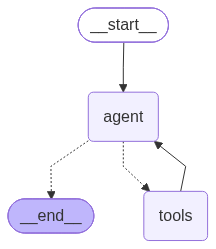

In [52]:
# Research Node:
research_agent=create_react_agent(
    llm,
    tools=[internal_tool_1,tavily_tool],
    prompt=make_system_prompt("You can only do research. Use the tool that you are binded with, you can use both of them" \
    " You are working with a content writer colleague.")
)

research_agent

In [53]:
#Research node
from typing import Literal
def research_node(state:MessagesState)-> Command[Literal["blog_generator",END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    # wrap in a human message, as not all providers allow
    # AI message at the last position of the input messages list
    result["messages"][-1] = HumanMessage(
        content=result["messages"][-1].content, name="researcher"
    )
    return Command(
        update={
            # share internal message history of research agent with other agents
            "messages": result["messages"],
        },
        goto=goto,
    )


In [54]:
# Blog Writer Agent:
blog_agent=create_react_agent(
    llm,
    tools=[],
    prompt=make_system_prompt(
        "You can only write a detailed blog. You are working with a researcher colleague."
    )
)

def blog_node(state: MessagesState) -> Command[Literal["researcher", END]]:
    result = blog_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "researcher")
    # wrap in a human message, as not all providers allow
    # AI message at the last position of the input messages list
    result["messages"][-1] = HumanMessage(
        content=result["messages"][-1].content, name="blog_generator"
    )
    return Command(
        update={
            # share internal message history of chart agent with other agents
            "messages": result["messages"],
        },
        goto=goto,
    )

C:\Users\Hrishikesh Kulkarni\AppData\Local\Temp\ipykernel_10124\1514438677.py:2: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  blog_agent=create_react_agent(


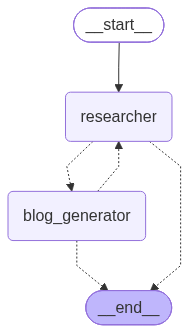

In [55]:
from langgraph.graph import StateGraph, START

workflow = StateGraph(MessagesState)
workflow.add_node("researcher", research_node)
workflow.add_node("blog_generator", blog_node)

workflow.add_edge(START, "researcher")
graph = workflow.compile()
graph

In [ ]:
response=graph.invoke({"messages":"Write a detailed blog on transformer variants in production deployments"})

In [ ]:
response["messages"][-1].content